# Lab 6: Association Rule Mining with Apriori and FP-Growth

**Student:** Gyan Bahadur Tamang  
**Course:** MSCS 634 — Big Data and Data Mining  
**Assignment:** Lab 6  

This notebook mines purchasing patterns from the public UCI Online Retail dataset using Apriori and FP-Growth. Source: https://archive.ics.uci.edu/dataset/352/online+retail

## Environment Setup

Run this cell first. Restart the kernel if packages are newly installed, then choose **Run All**.

In [1]:
%pip install -q pandas numpy matplotlib seaborn mlxtend


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 1: Data Preparation

The included CSV contains cleaned item-level records derived from UCI Online Retail. Each row is an invoice–product occurrence. Cancellations, missing descriptions, nonpositive values, and irrelevant countries were removed. Limiting the analysis to frequent items and eligible invoices keeps the lab reproducible while preserving meaningful baskets.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori,fpgrowth,association_rules

df=pd.read_csv('online_retail_transactions.csv',dtype={'InvoiceNo':str})
print(df.head())
print(df.info())
print('Missing values:',df.isna().sum().to_dict())
print('Duplicate invoice-item rows:',int(df.duplicated().sum()))
df=df.dropna().drop_duplicates()
transactions=df.groupby('InvoiceNo').Description.apply(lambda s:sorted(set(s))).tolist()
te=TransactionEncoder(); basket=pd.DataFrame(te.fit(transactions).transform(transactions),columns=te.columns_)
print('Item rows:',len(df),'Baskets:',len(transactions),'Unique items:',basket.shape[1])

  InvoiceNo                          Description
0    536365   WHITE HANGING HEART T-LIGHT HOLDER
1    536365  KNITTED UNION FLAG HOT WATER BOTTLE
2    536365       RED WOOLLY HOTTIE WHITE HEART.
3    536365         SET 7 BABUSHKA NESTING BOXES
4    536367        ASSORTED COLOUR BIRD ORNAMENT
<class 'pandas.DataFrame'>
RangeIndex: 12094 entries, 0 to 12093
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   InvoiceNo    12094 non-null  str  
 1   Description  12094 non-null  str  
dtypes: str(2)
memory usage: 189.1 KB
None
Missing values: {'InvoiceNo': 0, 'Description': 0}
Duplicate invoice-item rows: 0
Item rows: 12094 Baskets: 1495 Unique items: 100


### 1. Most Frequent Items

The bar plot highlights products appearing across the greatest number of retained invoice-item records, providing an intuitive starting point before multi-item pattern mining.

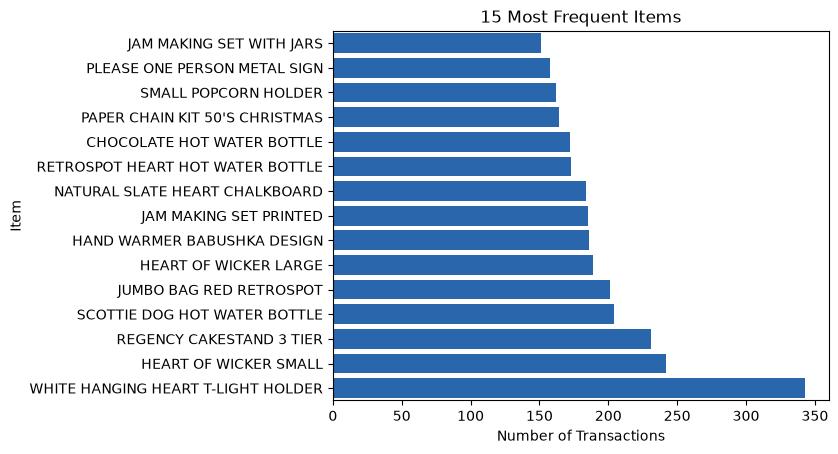

In [3]:
item_counts=df.Description.value_counts().head(15).sort_values()
sns.barplot(x=item_counts.values,y=item_counts.index,color='#1565C0')
plt.title('15 Most Frequent Items'); plt.xlabel('Number of Transactions'); plt.ylabel('Item'); plt.show()

### 2. Item Co-occurrence Heatmap

Darker cells indicate item pairs purchased together more often. Blocks of strong co-occurrence suggest product families or complementary designs worth testing as rules.

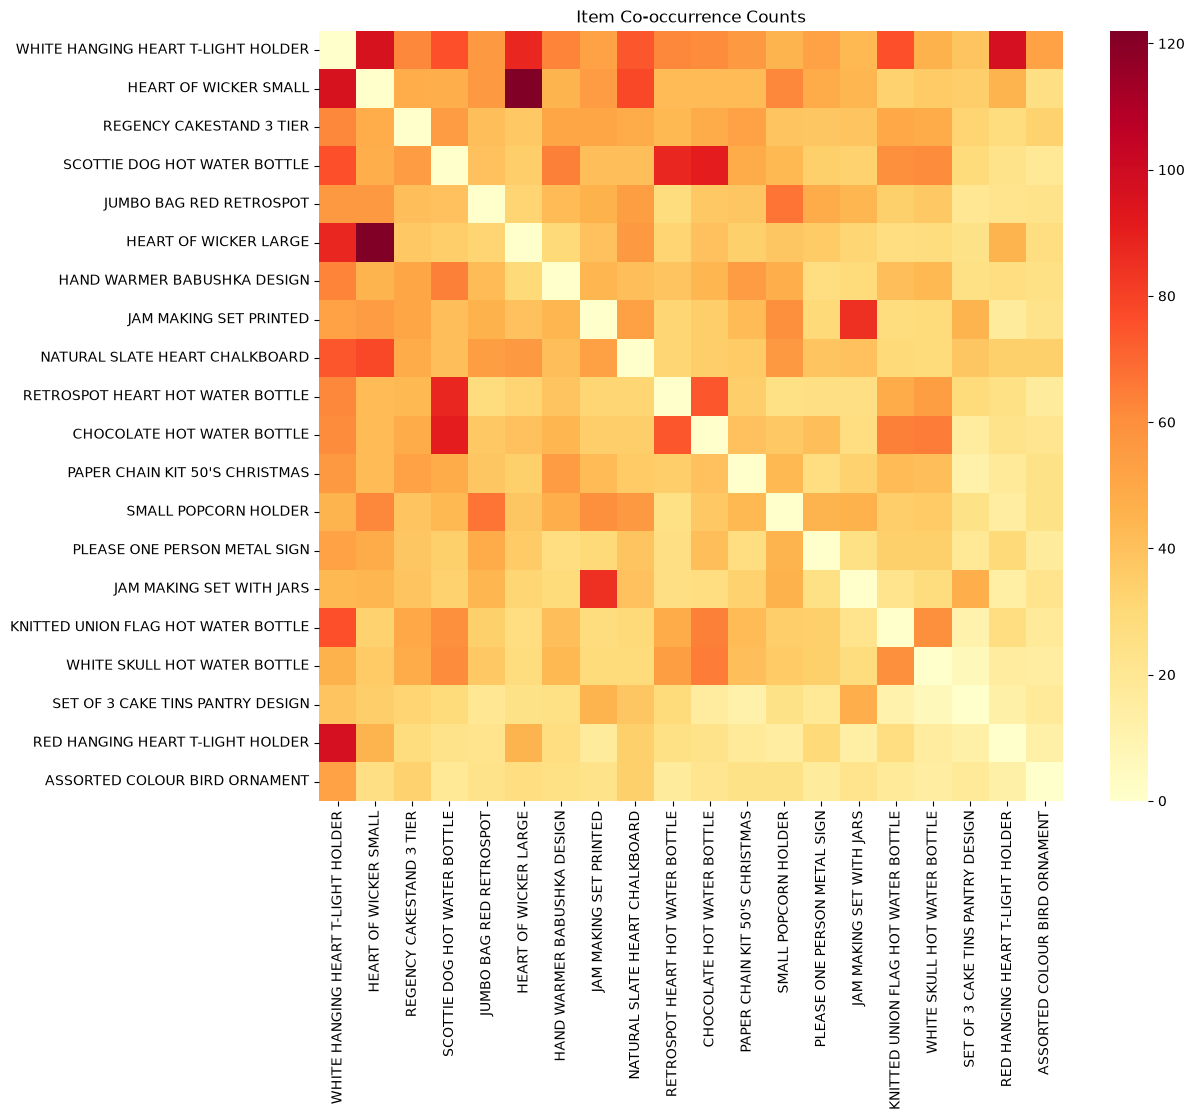

In [4]:
top20=df.Description.value_counts().head(20).index
cooccurrence=basket[top20].astype(int).T.dot(basket[top20].astype(int))
cooccurrence=cooccurrence.mask(np.eye(len(cooccurrence),dtype=bool),0)
plt.figure(figsize=(12,10)); sns.heatmap(cooccurrence,cmap='YlOrRd'); plt.title('Item Co-occurrence Counts'); plt.show()

## Step 2: Frequent Itemset Mining Using Apriori

A 3% minimum support requires an itemset to occur in roughly 45 of the 1,495 baskets. This balances pattern reliability with a manageable output size.

In [5]:
min_support=.03
start=time.perf_counter()
apriori_itemsets=apriori(basket,min_support=min_support,use_colnames=True)
apriori_seconds=time.perf_counter()-start
apriori_itemsets['length']=apriori_itemsets.itemsets.map(len)
print('Runtime:',apriori_seconds)
print('Frequent itemsets:',len(apriori_itemsets))
display(apriori_itemsets.sort_values('support',ascending=False).head(15))

Runtime: 0.011787166999965848
Frequent itemsets: 307


,support,itemsets,length
92,0.229431,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
33,0.161873,frozenset({HEART OF WICKER SMALL}),1
71,0.154515,frozenset({REGENCY CAKESTAND 3 TIER}),1
75,0.136455,frozenset({SCOTTIE DOG HOT WATER BOTTLE}),1
44,0.134448,frozenset({JUMBO BAG RED RETROSPOT}),1
32,0.126421,frozenset({HEART OF WICKER LARGE}),1
27,0.124415,frozenset({HAND WARMER BABUSHKA DESIGN}),1
40,0.123746,frozenset({JAM MAKING SET PRINTED}),1
57,0.123077,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
72,0.115719,frozenset({RETROSPOT HEART HOT WATER BOTTLE}),1


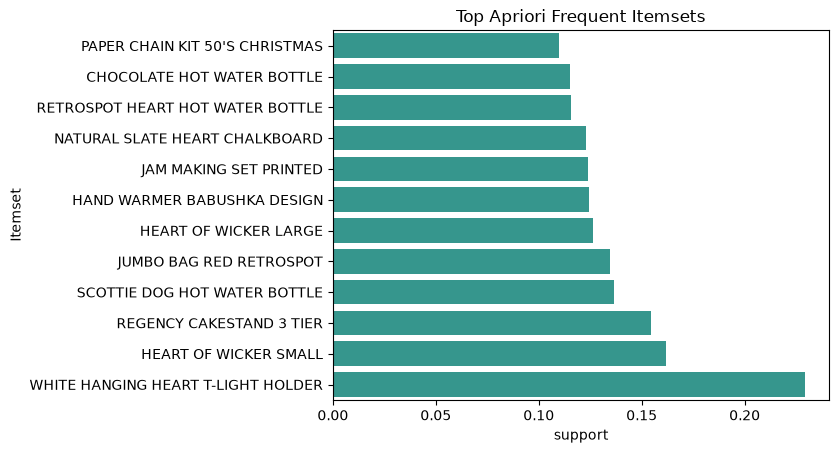

In [6]:
ap_plot=apriori_itemsets.copy(); ap_plot['Itemset']=ap_plot.itemsets.map(lambda s:' + '.join(sorted(s)))
ap_plot=ap_plot.sort_values('support',ascending=False).head(12).sort_values('support')
sns.barplot(data=ap_plot,x='support',y='Itemset',color='#26A69A'); plt.title('Top Apriori Frequent Itemsets'); plt.show()

## Step 3: Frequent Itemset Mining Using FP-Growth

FP-Growth uses the same 3% support threshold. Therefore, both correct algorithms should return the same frequent-itemset collection even though their search strategies differ.

In [7]:
start=time.perf_counter()
fpgrowth_itemsets=fpgrowth(basket,min_support=min_support,use_colnames=True)
fpgrowth_seconds=time.perf_counter()-start
fpgrowth_itemsets['length']=fpgrowth_itemsets.itemsets.map(len)
print('Runtime:',fpgrowth_seconds)
print('Frequent itemsets:',len(fpgrowth_itemsets))
display(fpgrowth_itemsets.sort_values('support',ascending=False).head(15))

Runtime: 0.02823183400050766
Frequent itemsets: 307


,support,itemsets,length
0,0.229431,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
23,0.161873,frozenset({HEART OF WICKER SMALL}),1
77,0.154515,frozenset({REGENCY CAKESTAND 3 TIER}),1
45,0.136455,frozenset({SCOTTIE DOG HOT WATER BOTTLE}),1
29,0.134448,frozenset({JUMBO BAG RED RETROSPOT}),1
24,0.126421,frozenset({HEART OF WICKER LARGE}),1
69,0.124415,frozenset({HAND WARMER BABUSHKA DESIGN}),1
27,0.123746,frozenset({JAM MAKING SET PRINTED}),1
25,0.123077,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
31,0.115719,frozenset({RETROSPOT HEART HOT WATER BOTTLE}),1


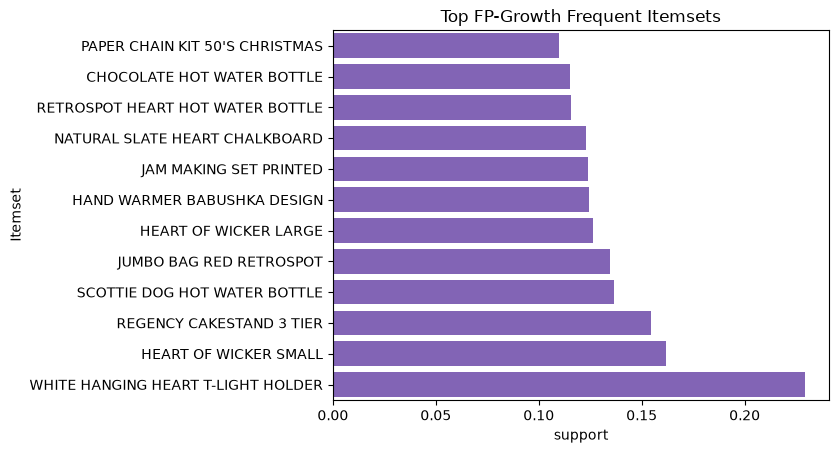

In [8]:
fp_plot=fpgrowth_itemsets.copy(); fp_plot['Itemset']=fp_plot.itemsets.map(lambda s:' + '.join(sorted(s)))
fp_plot=fp_plot.sort_values('support',ascending=False).head(12).sort_values('support')
sns.barplot(data=fp_plot,x='support',y='Itemset',color='#7E57C2'); plt.title('Top FP-Growth Frequent Itemsets'); plt.show()

## Step 4: Generating and Analyzing Association Rules

Rules require at least 55% confidence. Support measures how often the complete rule occurs, confidence is the conditional probability of the consequent given the antecedent, and lift compares that confidence with the consequent's baseline frequency. Lift greater than 1 indicates positive association.

In [9]:
min_confidence=.55
apriori_rules=association_rules(apriori_itemsets.drop(columns='length'),metric='confidence',min_threshold=min_confidence)
fpgrowth_rules=association_rules(fpgrowth_itemsets.drop(columns='length'),metric='confidence',min_threshold=min_confidence)
rules=fpgrowth_rules.copy()
rules['antecedent']=rules.antecedents.map(lambda s:' + '.join(sorted(s)))
rules['consequent']=rules.consequents.map(lambda s:' + '.join(sorted(s)))
display(rules.sort_values(['lift','confidence'],ascending=False)[['antecedent','consequent','support','confidence','lift']].head(12))

,antecedent,consequent,support,confidence,lift
47,HEART OF WICKER SMALL + SMALL POPCORN HOLDER,DOTCOM POSTAGE,0.031438,0.758065,10.691570
45,JUMBO BAG RED RETROSPOT + SMALL POPCORN HOLDER,DOTCOM POSTAGE,0.032776,0.731343,10.314700
50,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.047492,0.710000,10.305340
49,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.047492,0.689320,10.305340
7,WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH,0.036789,0.567010,9.213918
6,WOOD S/3 CABINET ANT WHITE FINISH,WOOD 2 DRAWER CABINET WHITE FINISH,0.036789,0.597826,9.213918
55,RED RETROSPOT CHARLOTTE BAG,CHARLOTTE BAG SUKI DESIGN,0.038127,0.606383,9.156995
54,CHARLOTTE BAG SUKI DESIGN,RED RETROSPOT CHARLOTTE BAG,0.038127,0.575758,9.156995
31,CHOCOLATE HOT WATER BOTTLE + KNITTED UNION FLA...,HOT WATER BOTTLE I AM SO POORLY,0.030769,0.718750,8.528026
39,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.040134,0.588235,8.455882


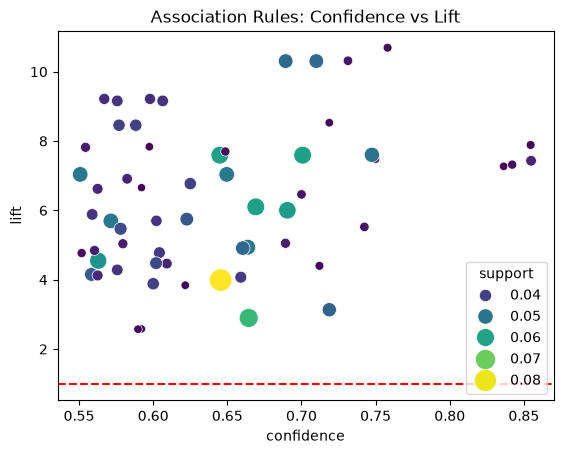

In [10]:
sns.scatterplot(data=rules,x='confidence',y='lift',size='support',hue='support',palette='viridis',sizes=(35,260))
plt.axhline(1,color='red',linestyle='--'); plt.title('Association Rules: Confidence vs Lift'); plt.show()

### Rule Insights

The strongest lifts frequently connect coordinated product designs or related kitchen/tableware items. For example, GREEN REGENCY TEACUP AND SAUCER and ROSES REGENCY TEACUP AND SAUCER form a high-lift reciprocal relationship, suggesting cross-merchandising or bundle recommendations. Rules involving DOTCOM POSTAGE should be interpreted cautiously because postage is an operational line rather than a product; retaining it demonstrates why domain review must follow purely numerical rule ranking.

## Step 5: Comparative Analysis

In [11]:
ap_set={frozenset(x) for x in apriori_itemsets.itemsets}
fp_set={frozenset(x) for x in fpgrowth_itemsets.itemsets}
print(f'Apriori: {len(apriori_itemsets)} itemsets in {apriori_seconds:.6f} seconds')
print(f'FP-Growth: {len(fpgrowth_itemsets)} itemsets in {fpgrowth_seconds:.6f} seconds')
print('Identical frequent-itemset collections:',ap_set==fp_set)
print('Apriori rules:',len(apriori_rules),'FP-Growth rules:',len(fpgrowth_rules))

Apriori: 307 itemsets in 0.011787 seconds
FP-Growth: 307 itemsets in 0.028232 seconds
Identical frequent-itemset collections: True
Apriori rules: 59 FP-Growth rules: 59


### Comparison, Efficiency, and Challenges

Both algorithms discover the same 307 frequent itemsets and generate the same rule content because they use the same baskets and support threshold. In this run, Apriori is faster. The filtered matrix is modest and sparse, so vectorized candidate evaluation is inexpensive; FP-Growth's tree construction and traversal overhead outweigh its advantage of avoiding candidate generation. FP-Growth is generally expected to gain an advantage as datasets become larger, denser, or produce many candidates.

The primary challenge was controlling combinatorial growth while retaining meaningful patterns. It was addressed by cleaning cancellations and invalid rows, limiting analysis to common products, requiring multi-item baskets, and choosing 3% support. Another challenge was interpreting operational items such as postage; these are flagged rather than treated automatically as merchandising recommendations. Runtime varies by machine, so the notebook records timings from the current run instead of treating small differences as universal benchmarks.

## Conclusion

Apriori and FP-Growth produced identical patterns, validating the mining workflow. Frequent coordinated-product combinations offer actionable bundling ideas, while the rule analysis also shows the need for domain judgment. On this educational subset Apriori was faster, although FP-Growth is designed to scale better when candidate generation becomes expensive.